# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = '1'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 2      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 2, файл lr6_варіант_02.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль "відтік" - бінарна мітка 0/1, тобто прогнозуємо належність клієнта до класу "піде", а не неперервну величину.

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: відтік лише 28%, тому модель y = 0 дає 72% точності, нічого не вміючи. AUC оцінює якість ранжування ризику без прив'язки до порогу

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: 1200 рядків замало для однієї згортки, стратифікація зберігає частку відтоку (~67 позитивів на фолд) у кожній частині, а повтори гасять випадковий розкид і дають розкид для парного порівняння моделей.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.280

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
summary = pd.DataFrame({
    'стовпець': raw.columns,
    'тип': raw.dtypes.astype(str).values,
    'унікальних': [raw[c].nunique(dropna=True) for c in raw.columns],
    'пропусків_%': [round(100 * raw[c].isna().mean(), 2) for c in raw.columns],
    'приклад': [raw[c].dropna().iloc[0] if raw[c].notna().any() else None
                for c in raw.columns],
}).sort_values('пропусків_%', ascending=False)

display(summary)

,стовпець,тип,унікальних,пропусків_%,приклад
23,дата_розірвання,str,278,72.00,2024-04-20
22,код_причини_закриття,str,5,72.00,ЦІН-02
17,середній_час_відповіді_хв,float64,263,35.75,13.8
14,трафік_ГБ,str,953,5.00,96.2
12,щомісячний_платіж,str,1122,4.00,304.94
16,аварій_на_ділянці_за_квартал,float64,6,3.00,3.0
2,стать,str,6,0.00,ж
3,місто,str,6,0.00,Самбір
0,id_клієнта,str,1200,0.00,K20000
1,вік,float64,61,0.00,42.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
text_in_num = raw['щомісячний_платіж'].notna() & pd.to_numeric(
    raw['щомісячний_платіж'], errors='coerce').isna()
print(raw.loc[text_in_num, 'щомісячний_платіж'].head())

excel_date = raw['трафік_ГБ'].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}')
print(raw.loc[excel_date, 'трафік_ГБ'])

mnar = raw['код_причини_закриття'].isna()
print(raw.groupby(mnar)['відтік'].agg(['size', 'mean']))

never_called = raw['середній_час_відповіді_хв'].isna()
print(raw.groupby(never_called)['кількість_звернень_у_підтримку'].agg(['min', 'max', 'size']))

4      210.63 грн
132    384.39 грн
137    266.78 грн
165    289.64 грн
221    268.59 грн
Name: щомісячний_платіж, dtype: str
617     1900-01-02 00:00:00
813     1900-01-02 00:00:00
1008    1900-01-01 00:00:00
Name: трафік_ГБ, dtype: str
                      size  mean
код_причини_закриття            
False                  336   1.0
True                   864   0.0
                           min  max  size
середній_час_відповіді_хв                
False                        1    6   771
True                         0    0   429


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'код_причини_закриття'    # назва стовпця
MNAR_MEANING           = 'Пропуск означає, що клієнт не розривав договір'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
import re

DATE_RE = re.compile(r'^\d{4}-\d{2}-\d{2}(?:[ T].*)?$|^\d{1,2}[./]\d{1,2}[./]\d{2,4}$')
NUM_RE  = re.compile(r'[-+]?\d[\d\s]*(?:[.,]\d+)?')


def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if pd.isna(v):
            return np.nan

        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp, np.datetime64)):
            return np.nan

        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)

        if isinstance(v, str):
            t = v.strip()
            if not t:
                return np.nan

            if DATE_RE.match(t):
                return np.nan

            m = NUM_RE.match(t)
            if not m:
                return np.nan

            raw_num = (m.group(0)
                       .replace(' ', '')
                       .replace('\xa0', '')
                       .replace(',', '.'))
            try:
                return float(raw_num)
            except ValueError:
                return np.nan

        return np.nan

    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []

    for c in d.columns:
        if c in drop or c == TARGET:
            continue

        s = d[c]

        if c == 'дата_підключення':
            dt = pd.to_datetime(s, errors='coerce')
            X[c] = dt.map(
                lambda t: t.toordinal() if pd.notna(t) else np.nan
            ).astype(float)
            log.append({'ознака': c, 'рішення': 'число',
                        'чому': 'дата -> порядковий день'})
            continue

        if pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            log.append({'ознака': c, 'рішення': 'число',
                        'чому': 'вже numeric'})
            continue

        num = to_number(s)
        present = int(s.notna().sum())
        parsed = int(num.notna().sum())
        share = parsed / present if present else 0.0

        if share > 0.8:
            X[c] = num.astype(float)
            log.append({'ознака': c, 'рішення': 'число',
                        'чому': 'розібрано %d%% значень' % round(100 * share)})
        else:
            clean = s.map(
                lambda v: v.strip().lower() if isinstance(v, str) else np.nan
            )
            X[c] = clean.astype('category')
            log.append({'ознака': c, 'рішення': 'категорія',
                        'чому': 'розібрано лише %d%% значень' % round(100 * share)})

    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 10


,ознака,рішення,чому
0,вік,число,вже numeric
1,стать,категорія,розібрано лише 0% значень
2,місто,категорія,розібрано лише 0% значень
3,філія,категорія,розібрано лише 0% значень
4,тариф,категорія,розібрано лише 0% значень
5,тип_підключення,категорія,розібрано лише 0% значень
6,спосіб_оплати,категорія,розібрано лише 0% значень
7,автоплатіж,категорія,розібрано лише 0% значень
8,кількість_послуг,число,вже numeric
9,місяців_обслуговування,число,вже numeric


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num_cols = X.select_dtypes(include=['number']).columns.tolist()
    cat_cols = X.select_dtypes(include=['category', 'object', 'string']).columns.tolist()

    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])

    transformers = []
    if num_cols:
        transformers.append(('num', num_pipe, num_cols))
    if cat_cols:
        transformers.append(('cat', cat_pipe, cat_cols))

    return Pipeline([
        ('prep', ColumnTransformer(transformers)),
        ('clf', clf),
    ])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.8 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'витік цілі'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

витік цілі


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    y_arr = np.asarray(y).astype(int)
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna().to_numpy()
        n_filled = int(filled.sum())
        n_missing = int((~filled).sum())

        if n_filled <= min_group or n_missing <= min_group:
            continue

        rows.append({
            'ознака': c,
            'заповнено': n_filled,
            'частка_відтоку_де_заповнено': float(y_arr[filled].mean()),
            'частка_відтоку_де_пропуск': float(y_arr[~filled].mean()),
            'показник': roc_auc_score(y_arr, filled.astype(int)),
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,код_причини_закриття,336,1.000000,0.000000,1.000000
5,дата_розірвання,336,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,771,0.308690,0.228438,0.545718
1,трафік_ГБ,1140,0.280702,0.266667,0.501653
0,щомісячний_платіж,1152,0.280382,0.270833,0.500909
2,аварій_на_ділянці_за_квартал,1164,0.275773,0.416667,0.489831


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'код_причини_закриття',
    'дата_розірвання'
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'дата_розірвання']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.966 ± 0.006


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',
]
HUMAN_LEAK_WHY = 'оцінку ставить менеджер під час або після розмови, а не перед'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.863 ± 0.014


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,клієнтів,частка_відтоку
філія,,
Ф-02 Захід,190,0.468421
Ф-01 Центр,191,0.439791
Ф-06 Приміська,198,0.212121
Ф-05 Північ,218,0.197248
Ф-03 Схід,209,0.196172
Ф-04 Південь,194,0.190722


,клієнтів,частка_відтоку
квартал,,
2023Q1,149,0.342282
2023Q2,144,0.277778
2023Q3,157,0.286624
2023Q4,172,0.296512
2024Q1,136,0.257353
2024Q2,126,0.246032
2024Q3,160,0.256250
2024Q4,156,0.269231


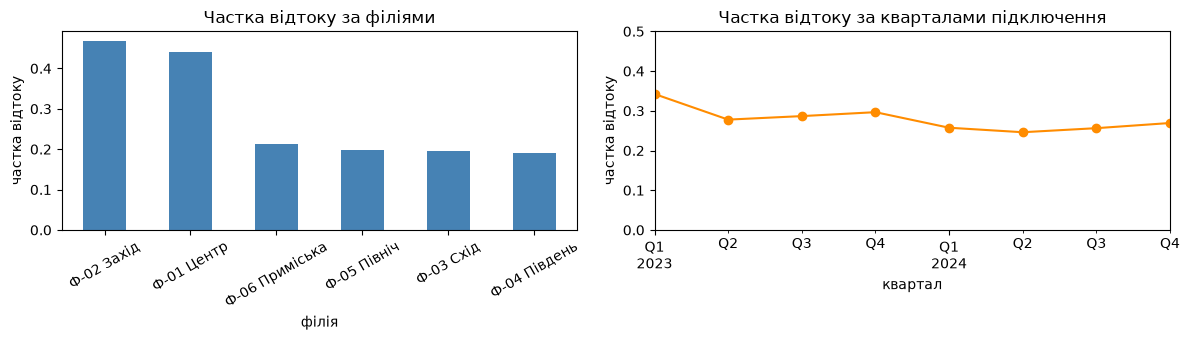

In [19]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
# Шукайте СХОДИНКУ, а не плавну зміну.
by_branch = raw.groupby('філія')['відтік'].agg(['size', 'mean'])
by_branch.columns = ['клієнтів', 'частка_відтоку']
by_branch = by_branch.sort_values('частка_відтоку', ascending=False)
display(by_branch)

raw['квартал'] = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')
by_quarter = raw.groupby('квартал')['відтік'].agg(['size', 'mean'])
by_quarter.columns = ['клієнтів', 'частка_відтоку']
display(by_quarter)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

by_branch['частка_відтоку'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Частка відтоку за філіями')
axes[0].set_ylabel('частка відтоку')
axes[0].tick_params(axis='x', rotation=30)

by_quarter['частка_відтоку'].plot(marker='o', ax=axes[1], color='darkorange')
axes[1].set_title('Частка відтоку за кварталами підключення')
axes[1].set_ylabel('частка відтоку')
axes[1].set_ylim(0, 0.5)

plt.tight_layout()
plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу
source = raw['філія'].isin(['Ф-01 Центр', 'Ф-02 Захід']).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.648
ті самі ознаки передбачають ВІДТІК  : AUC 0.813 ± 0.024


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.966
3. мінус оцінки людини,21,0.863
4. мінус артефакт збору,21,0.813


чесне число: 0.813 ± 0.024


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'залишити, але звітувати окремо'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = (
    'Філія дає різку сходинку 45% проти 20%, і ця різниця стабільна '
    'в часі та всередині тарифів, тому вона не схожа на випадковий шум. '
    'Водночас AUC джерела 0.648 показує, що філія лише частково '
    'закодована в інших ознаках, тож повне викидання стовпця втрачає '
    'реальний сигнал, який модель не може відновити. Але через розмір '
    'різниці не можна подавати один загальний AUC як такий, що діє для '
    'всіх філій: треба звітувати метрики окремо по філіях і перевіряти '
    'модель груповою схемою, інакше сильна якість на Ф-01 і Ф-02 '
    'замаскує проблеми на решті філій.'
)
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

залишити, але звітувати окремо — Філія дає різку сходинку 45% проти 20%, і ця різниця стабільна в часі та всередині тарифів, тому вона не схожа на випадковий шум. Водночас AUC джерела 0.648 показує, що філія лише частково закодована в інших ознаках, тож повне викидання стовпця втрачає реальний сигнал, який модель не може відновити. Але через розмір різниці не можна подавати один загальний AUC як такий, що діє для всіх філій: треба звітувати метрики окремо по філіях і перевіряти модель груповою схемою, інакше сильна якість на Ф-01 і Ф-02 замаскує проблеми на решті філій.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [24]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(
                                max_depth=5,
                                min_samples_leaf=20,
                                random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(
                                n_estimators=300,
                                random_state=SEED,
                                n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(
                                max_iter=200,
                                learning_rate=0.05,
                                random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 5), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.81291,0.024,0.6
одне дерево,0.76202,0.027,0.4
випадковий ліс,0.82877,0.029,15.0
гістограмний бустинг,0.82901,0.021,7.4


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [25]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця b - a, півширина 95% інтервалу)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    assert len(a) == len(b), 'моделі оцінені на різних згортках'

    d = b - a
    m = d.mean()
    t = stats.t.ppf(0.975, len(d) - 1)
    h = t * d.std(ddof=1) / np.sqrt(len(d))
    return m, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0159 ± 0.0097   значуще
гістограмний бустинг   проти логістичної: +0.0161 ± 0.0090   значуще


In [26]:
CHOSEN_MODEL = 'гістограмний бустинг'     # назва з MODELS
CHOSEN_WHY = 'гістограмний бустинг та випадковий ліс мають значущий приріст, але бустинг виконується швидше'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: гістограмний бустинг — гістограмний бустинг та випадковий ліс мають значущий приріст, але бустинг виконується швидше


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [27]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()

    # 1) Клієнт жодного разу не звертався в підтримку.
    # Гіпотеза: відсутність звернень означає, що клієнт не стикався з
    # проблемами, тому ймовірність відтоку нижча. Медіанна імпутація
    # цей сигнал стирає, тому повертаємо його окремою бінарною ознакою.
    F['не_звертався'] = F['середній_час_відповіді_хв'].isna().astype(int)

    # 2) Трафік на одну гривню платежу.
    # Гіпотеза: якщо клієнт платить багато, але використовує мало трафіку,
    # він отримує мало цінності за гроші і частіше йде.
    F['трафік_на_гривню'] = F['трафік_МБ'] / F['щомісячний_платіж']

    # 3) Кількість звернень у підтримку на місяць обслуговування.
    # Гіпотеза: часті звернення означають постійні проблеми, тому
    # такі клієнти частіше розривають договір.
    F['звернень_на_місяць'] = (
        F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    )

    # 4) Аварії на ділянці на місяць обслуговування.
    # Гіпотеза: більше аварій на мережі означає гіршу якість зв'язку,
    # що підвищує ризик відтоку.
    F['аварій_на_місяць'] = (
        F['аварій_на_ділянці_за_квартал'] / (F['місяців_обслуговування'] + 1)
    )

    # 5) Платіж на одну послугу.
    # Гіпотеза: висока ціна за одиницю послуги сприймається як погана
    # цінність, тому підвищує ризик відтоку.
    F['ціна_за_послугу'] = F['щомісячний_платіж'] / F['кількість_послуг']

    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 21 ознак, стало 26


In [28]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.813 ± 0.024
приріст проти базового набору: -0.0002 ± 0.0020   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [29]:
FEATURES_VS_MODEL = (
    'Нові ознаки не дали нічого. Складна модель дала '
    '+0.0161 ± 0.0090 і коштувала 7.4 секунд '
    'на 100 навчань проти 0.6 у логістичної регресії. Отже, за '
    'якістю виграла Складна модель, але ціною 12x більшого '
    'часу. Якщо приріст моделі теж у межах шуму, правильний висновок: '
    'не ускладнювати модель і не додавати ці ознаки.'
)
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Нові ознаки не дали нічого. Складна модель дала +0.0161 ± 0.0090 і коштувала 7.4 секунд на 100 навчань проти 0.6 у логістичної регресії. Отже, за якістю виграла Складна модель, але ціною 12x більшого часу. Якщо приріст моделі теж у межах шуму, правильний висновок: не ускладнювати модель і не додавати ці ознаки.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [30]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.800
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
вік,0.088649
щомісячний_платіж,0.088401
код_тарифного_плану,0.087610
трафік_на_гривню,0.086310
трафік_МБ,0.058016
трафік_ГБ,0.050682
ціна_за_послугу,0.050447
звернень_на_місяць,0.048925
швидкість_тарифу_Мбіт,0.047674
місяців_обслуговування,0.046923


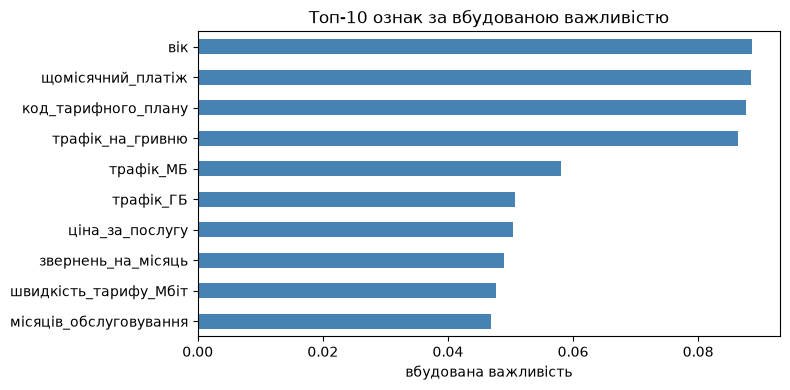

In [33]:
prep = model.named_steps['prep']
clf = model.named_steps['clf']

feat_names = prep.get_feature_names_out()
importances = clf.feature_importances_


def to_original(name):
    """Повертає вихідну ознаку для імені після перетворення."""
    if name.startswith('num__'):
        return name[len('num__'):]

    rest = name[len('cat__'):]
    candidates = [c for c in FINAL_X.columns if rest.startswith(str(c) + '_')]
    if candidates:
        return max(candidates, key=len)
    return rest.rsplit('_', 1)[0]


gini_imp = (
    pd.Series(importances, index=[to_original(n) for n in feat_names])
    .groupby(level=0)
    .sum()
    .sort_values(ascending=False)
)

display(gini_imp.head(10).to_frame('вбудована важливість'))

top10 = gini_imp.head(10).sort_values()
ax = top10.plot(kind='barh', figsize=(8, 4), color='steelblue')
ax.set_xlabel('вбудована важливість')
ax.set_title('Топ-10 ознак за вбудованою важливістю')
plt.tight_layout()
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [34]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.073789
трафік_на_гривню,0.027107
аварій_на_місяць,0.015993
місяців_обслуговування,0.012313
звернень_на_місяць,0.008733
щомісячний_платіж,0.007657
швидкість_тарифу_Мбіт,0.006556
трафік_МБ,0.005491
автоплатіж,0.004763
трафік_ГБ,0.003811


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [35]:
cmp_imp = pd.DataFrame({
    'вбудована': gini_imp,
    'перестановочна': perm_imp.reindex(gini_imp.index),
}).dropna().sort_values('вбудована', ascending=False)

display(cmp_imp.head(10))
print(cmp_imp.loc['код_тарифного_плану'])

,вбудована,перестановочна
вік,0.088649,0.073789
щомісячний_платіж,0.088401,0.007657
код_тарифного_плану,0.087610,0.000403
трафік_на_гривню,0.086310,0.027107
трафік_МБ,0.058016,0.005491
трафік_ГБ,0.050682,0.003811
ціна_за_послугу,0.050447,0.000505
звернень_на_місяць,0.048925,0.008733
швидкість_тарифу_Мбіт,0.047674,0.006556
місяців_обслуговування,0.046923,0.012313


вбудована         0.087610
перестановочна    0.000403
Name: код_тарифного_плану, dtype: float64


In [36]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = (
    "Це категоріальна ознака з 40 рівнями. Після одиничного кодування вона "
    "перетворюється на 39 бінарних стовпців, і дерево отримує багато "
    "можливих розбиттів. Вбудована важливість сумує 39 маленьких зменшень "
    "неоднорідності і дає 0.088, третє місце. Перестановка ж показує, що "
    "без цієї ознаки якість не падає, отже вона важлива лише на тренуванні."
)
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [37]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
num_cols = FINAL_X.select_dtypes(include='number').columns
corr = FINAL_X[num_cols].corr()

display(corr.round(2))

pairs = []
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) > 0.97:
            pairs.append((a, b, round(r, 4)))

print(pairs)

,вік,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,трафік_МБ,індекс_лояльності_CRM,дата_підключення,не_звертався,трафік_на_гривню,звернень_на_місяць,аварій_на_місяць,ціна_за_послугу
вік,1.00,-0.01,-0.01,0.06,0.09,0.04,0.01,0.04,0.02,0.01,0.01,-0.00,-0.03,0.02,-0.03,0.05,0.03,0.09
кількість_послуг,-0.01,1.00,-0.00,0.04,0.45,-0.02,-0.05,0.04,-0.01,-0.07,-0.04,0.01,0.12,-0.04,-0.28,0.01,0.01,-0.70
місяців_обслуговування,-0.01,-0.00,1.00,-0.04,-0.01,-0.06,-0.04,-0.01,0.01,0.02,-0.04,-0.03,-0.01,0.01,-0.01,-0.38,-0.33,-0.02
швидкість_тарифу_Мбіт,0.06,0.04,-0.04,1.00,0.73,0.01,0.01,-0.00,-0.00,-0.02,0.01,-0.02,0.20,0.02,-0.25,-0.01,0.02,0.47
щомісячний_платіж,0.09,0.45,-0.01,0.73,1.00,0.00,-0.03,0.01,-0.00,-0.06,-0.02,0.01,0.03,0.01,-0.41,-0.01,0.02,0.24
знижка_відсоток,0.04,-0.02,-0.06,0.01,0.00,1.00,-0.01,0.01,-0.00,0.01,0.00,0.03,0.04,0.00,0.00,0.05,0.02,0.04
трафік_ГБ,0.01,-0.05,-0.04,0.01,-0.03,-0.01,1.00,0.03,-0.02,-0.04,1.00,0.05,0.00,-0.02,0.88,0.05,0.02,0.03
кількість_звернень_у_підтримку,0.04,0.04,-0.01,-0.00,0.01,0.01,0.03,1.00,-0.00,-0.04,0.02,0.04,-0.01,-0.76,-0.02,0.62,0.00,-0.04
аварій_на_ділянці_за_квартал,0.02,-0.01,0.01,-0.00,-0.00,-0.00,-0.02,-0.00,1.00,-0.02,-0.02,-0.02,-0.05,0.02,-0.01,-0.01,0.68,0.01
середній_час_відповіді_хв,0.01,-0.07,0.02,-0.02,-0.06,0.01,-0.04,-0.04,-0.02,1.00,-0.03,-0.00,-0.07,NaN,0.01,-0.07,-0.02,0.04


[('трафік_ГБ', 'трафік_МБ', np.float64(0.9997))]


In [39]:
DUP_PAIR = ['трафік_МБ', 'трафік_ГБ']       # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
Xtr2 = Xtr.drop(columns=[DUP_PAIR[1]])
Xte2 = Xte.drop(columns=[DUP_PAIR[1]])

model2 = make_pipe(
    Xtr2,
    RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
).fit(Xtr2, ytr)

perm2 = permutation_importance(
    model2, Xte2, yte, n_repeats=10, random_state=SEED, scoring='roc_auc'
)
perm_imp2 = pd.Series(perm2.importances_mean, index=Xtr2.columns)

imp_after = perm_imp2[DUP_PAIR[0]]
print('важливість %s без пари: %+.4f' % (DUP_PAIR[0], imp_after))

у повній моделі:
   трафік_МБ                    +0.0055
   трафік_ГБ                    +0.0038
важливість трафік_МБ без пари: +0.0106


In [40]:
DUP_EXPLANATION = (
    'Трафік_ГБ і трафік_МБ вимірюють той самий трафік у гігабайтах і '
    'мегабайтах, кореляція 0.9997. У повній моделі перестановочна '
    'важливість кожної з них мала: 0.0038 і 0.0055. Коли прибрали '
    'трафік_ГБ, важливість трафік_МБ зросла до %+.4f. Це не вада методу: '
    'перестановочна важливість відповідає на питання "наскільки впаде '
    'якість, якщо перемішати цю ознаку", а не "наскільки важлива ця '
    'інформація взагалі". Поки в моделі є друга копія, перемішування '
    'однієї нічого не ламає. Тому низька важливість не означає, що '
    'ознаку можна викинути: можливо, її інформація просто дублюється.'
    % imp_after
)
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Трафік_ГБ і трафік_МБ вимірюють той самий трафік у гігабайтах і мегабайтах, кореляція 0.9997. У повній моделі перестановочна важливість кожної з них мала: 0.0038 і 0.0055. Коли прибрали трафік_ГБ, важливість трафік_МБ зросла до +0.0106. Це не вада методу: перестановочна важливість відповідає на питання "наскільки впаде якість, якщо перемішати цю ознаку", а не "наскільки важлива ця інформація взагалі". Поки в моделі є друга копія, перемішування однієї нічого не ламає. Тому низька важливість не означає, що ознаку можна викинути: можливо, її інформація просто дублюється.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки: ['вік', 'трафік_на_гривню', 'аварій_на_місяць']


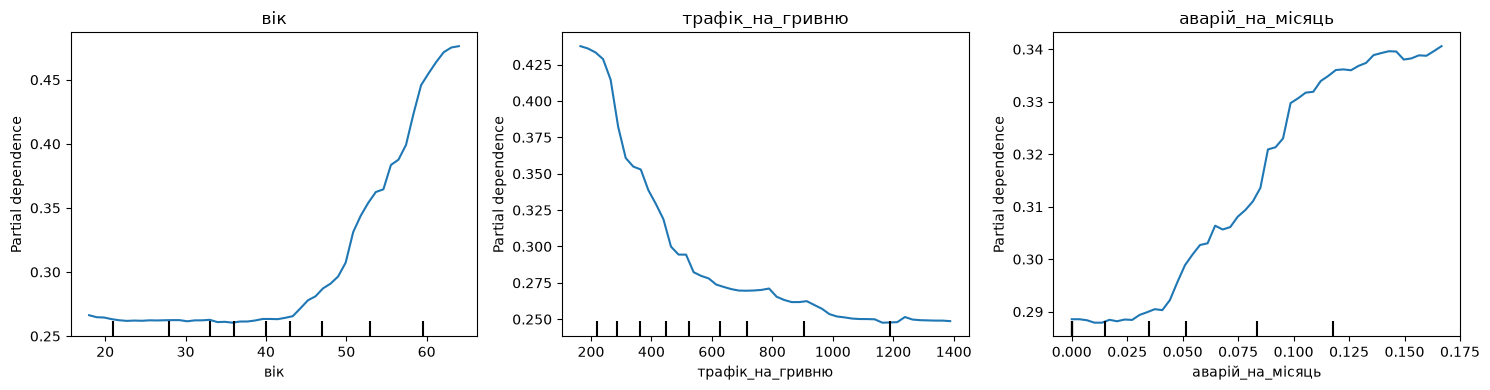

In [41]:
from sklearn.inspection import PartialDependenceDisplay

top3_num = [c for c in perm_imp.index
            if pd.api.types.is_numeric_dtype(FINAL_X[c])][:3]
print('три найважливіші числові ознаки:', top3_num)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feat in zip(axes, top3_num):
    mask = Xte[feat].notna()
    PartialDependenceDisplay.from_estimator(
        model,
        Xte[mask],
        [feat],
        kind='average',
        grid_resolution=50,
        ax=ax,
    )
    ax.set_title(feat)

plt.tight_layout()
plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

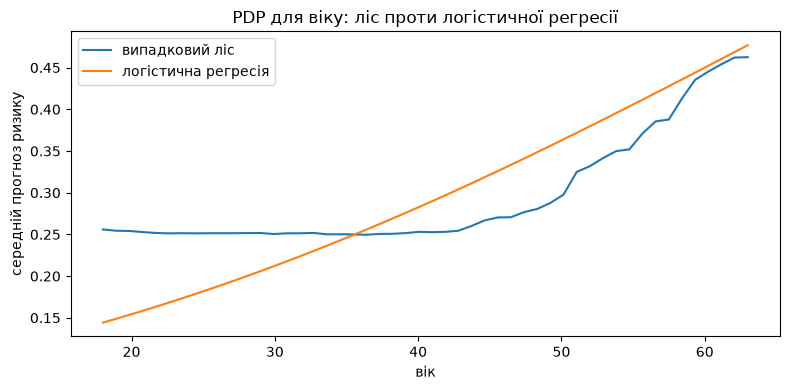

In [42]:
from sklearn.inspection import partial_dependence

NONLINEAR_FEATURE = 'вік'

logit_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

pd_forest = partial_dependence(
    model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=50
)
pd_logit = partial_dependence(
    logit_model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=50
)

grid = pd_forest['grid_values'][0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, pd_forest['average'][0], label='випадковий ліс', color='tab:blue')
ax.plot(grid, pd_logit['average'][0], label='логістична регресія', color='tab:orange')
ax.set_xlabel('вік')
ax.set_ylabel('середній прогноз ризику')
ax.set_title('PDP для віку: ліс проти логістичної регресії')
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
NONLINEAR_MEANING = (
    'Ризик відтоку майже не змінюється від 18 до 40 років, а після 40 '
    'швидко зростає. Мінімум припадає приблизно на 30 років. Лінійна '
    'модель малює пряму, яка занижує ризик для молодих і завищує для '
    'середнього віку, тому не відтворює плоску ділянку до 40 років.'
)

NONLINEAR_FIX = (
    'Додати ознаку (вік - 30)^2, тобто квадрат відхилення від віку, '
    'у якому ризик мінімальний. Це дає лінійній моделі U-подібну форму '
    'і дозволяє підняти ризик для молодих та старших клієнтів.'
)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Ризик відтоку майже не змінюється від 18 до 40 років, а після 40 швидко зростає. Мінімум припадає приблизно на 30 років. Лінійна модель малює пряму, яка занижує ризик для молодих і завищує для середнього віку, тому не відтворює плоску ділянку до 40 років.
Додати ознаку (вік - 30)^2, тобто квадрат відхилення від віку, у якому ризик мінімальний. Це дає лінійній моделі U-подібну форму і дозволяє підняти ризик для молодих та старших клієнтів.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [44]:
FINAL_X_quad = FINAL_X.copy()
FINAL_X_quad['вік_квадрат'] = (FINAL_X_quad['вік'] - 30) ** 2

auc_base_x5 = cross_val_score(
    make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc'
)
auc_quad = cross_val_score(
    make_pipe(FINAL_X_quad, logreg()), FINAL_X_quad, y, cv=cv, scoring='roc_auc'
)

m, h = paired(auc_base_x5, auc_quad)
QUAD_GAIN = m

print('без квадрата: AUC %.3f ± %.3f' % (auc_base_x5.mean(), auc_base_x5.std()))
print('з квадратом : AUC %.3f ± %.3f' % (auc_quad.mean(), auc_quad.std()))
print('приріст: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

без квадрата: AUC 0.813 ± 0.024
з квадратом : AUC 0.838 ± 0.028
приріст: +0.0253 ± 0.0051   значуще


In [45]:
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0253


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

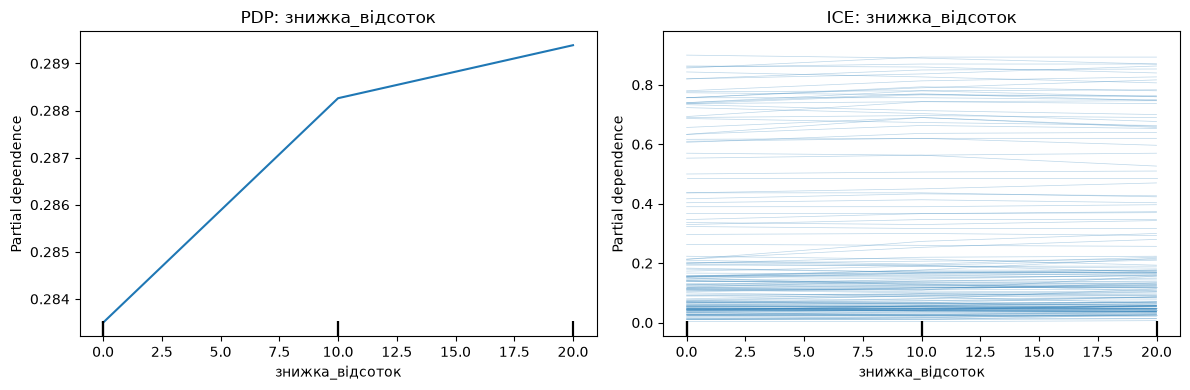

In [50]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
from sklearn.inspection import PartialDependenceDisplay

values = {'знижка_відсоток': [0, 10, 20]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

PartialDependenceDisplay.from_estimator(
    model,
    FINAL_X,
    ['знижка_відсоток'],
    kind='average',
    custom_values=values,
    ax=axes[0],
)
axes[0].set_title('PDP: знижка_відсоток')

PartialDependenceDisplay.from_estimator(
    model,
    FINAL_X,
    ['знижка_відсоток'],
    kind='individual',
    custom_values=values,
    subsample=150,
    random_state=SEED,
    ax=axes[1],
)
axes[1].set_title('ICE: знижка_відсоток')

plt.tight_layout()
plt.show()

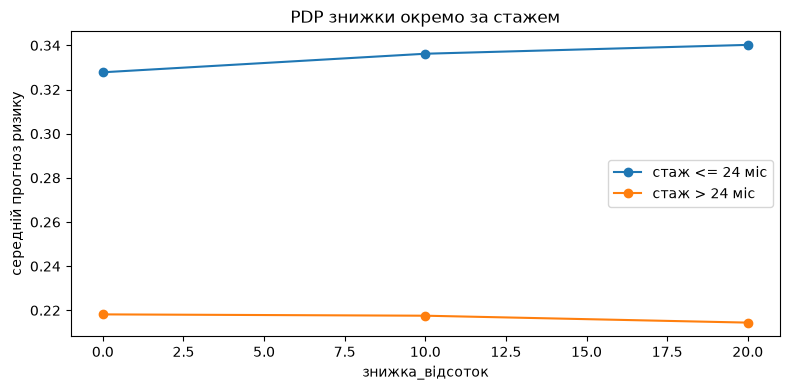

In [51]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
short = FINAL_X['місяців_обслуговування'] <= 24
long = FINAL_X['місяців_обслуговування'] > 24

discount_values = sorted(FINAL_X['знижка_відсоток'].unique())

fig, ax = plt.subplots(figsize=(8, 4))

for label, mask in [('стаж <= 24 міс', short), ('стаж > 24 міс', long)]:
    means = []
    for v in discount_values:
        X_tmp = FINAL_X[mask].copy()
        X_tmp['знижка_відсоток'] = v
        means.append(model.predict_proba(X_tmp)[:, 1].mean())
    ax.plot(discount_values, means, marker='o', label=label)

ax.set_xlabel('знижка_відсоток')
ax.set_ylabel('середній прогноз ризику')
ax.set_title('PDP знижки окремо за стажем')
ax.legend()
plt.tight_layout()
plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [52]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
raw['група_стажу'] = np.where(
    raw['місяців_обслуговування'] <= 24, 'до 24 міс', 'понад 24 міс'
)

interaction = (
    raw.groupby(['група_стажу', 'знижка_відсоток'])['відтік']
    .agg(['size', 'mean'])
    .reset_index()
)
interaction.columns = ['група_стажу', 'знижка_відсоток', 'клієнтів', 'частка_відтоку']
display(interaction)

pivot = interaction.pivot(
    index='група_стажу',
    columns='знижка_відсоток',
    values='частка_відтоку',
)
display(pivot.round(3))

,група_стажу,знижка_відсоток,клієнтів,частка_відтоку
0,до 24 міс,0,290,0.268966
1,до 24 міс,10,250,0.376000
2,до 24 міс,20,175,0.480000
3,понад 24 міс,0,221,0.235294
4,понад 24 міс,10,134,0.141791
5,понад 24 міс,20,130,0.069231


знижка_відсоток,0,10,20
група_стажу,,,
до 24 міс,0.269,0.376,0.480
понад 24 міс,0.235,0.142,0.069


In [53]:
INTERACTION_FOUND = (
    'У сирих даних знижка діє протилежно в двох групах стажу. У клієнтів '
    'до 24 місяців частка відтоку зростає зі знижкою: 0.269 при 0%, 0.376 '
    'при 10% і 0.480 при 20%. У клієнтів понад 24 місяців вона спадає: '
    '0.235, 0.142 і 0.069. Модель цю картину не відтворює: її PDP майже '
    'плаский (0.2835-0.2895), а ICE-криві майже горизонтальні. Отже, '
    'питання не до PDP, а до моделі: вона не вивчила взаємодію знижки зі стажем.'
)

BUSINESS_ACTION = (
    'Не давати знижку всім підряд. Для клієнтів із довгим стажем знижка '
    'асоційована з нижчим відтоком, тому її можна розглядати як інструмент '
    'утримання. Для клієнтів із коротким стажем знижка частіше стоїть поруч '
    'із високим відтоком, тому сама по собі вона не вирішує проблему: '
    'спершу треба зрозуміти причину ризику. Оскільки модель не відтворює '
    'цю взаємодію, спиратися на її PDP для рішення про знижку не можна. '
    'Треба або додати ознаку взаємодії, або перевірити ефект експериментом.'
)
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

У сирих даних знижка діє протилежно в двох групах стажу. У клієнтів до 24 місяців частка відтоку зростає зі знижкою: 0.269 при 0%, 0.376 при 10% і 0.480 при 20%. У клієнтів понад 24 місяців вона спадає: 0.235, 0.142 і 0.069. Модель цю картину не відтворює: її PDP майже плаский (0.2835-0.2895), а ICE-криві майже горизонтальні. Отже, питання не до PDP, а до моделі: вона не вивчила взаємодію знижки зі стажем.
Не давати знижку всім підряд. Для клієнтів із довгим стажем знижка асоційована з нижчим відтоком, тому її можна розглядати як інструмент утримання. Для клієнтів із коротким стажем знижка частіше стоїть поруч із високим відтоком, тому сама по собі вона не вирішує проблему: спершу треба зрозуміти причину ризику. Оскільки модель не відтворює цю взаємодію, спиратися на її PDP для рішення про знижку не можна. Треба або додати ознаку взаємодії, або перевірити ефект експериментом.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [54]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 80)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

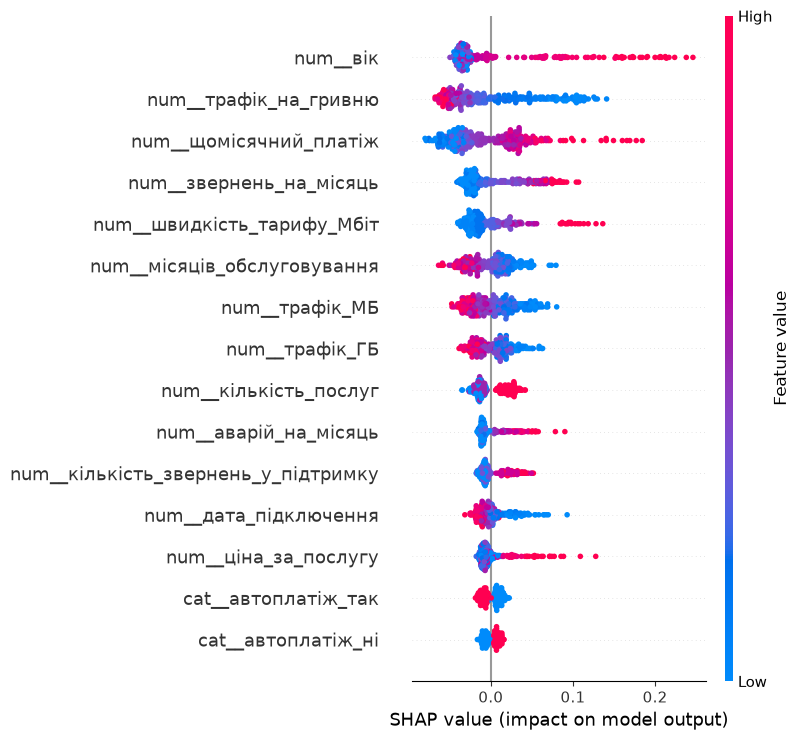

In [55]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(
    sv1,
    Xte_t[:SAMPLE],
    feature_names=feat_names,
    max_display=15,
)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [57]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
risk = model.predict_proba(Xte)[:SAMPLE, 1][idx]
print('ризик клієнта: %.3f' % risk)

client = Xte.iloc[idx]
row = pd.Series(sv1[idx], index=feat_names)
top3 = row.reindex(row.abs().sort_values(ascending=False).index).head(3)

print('\nтри найбільші внески:')
for name, val in top3.items():
    print('%+0.3f  %s' % (val, name))

ризик клієнта: 0.767

три найбільші внески:
+0.159  num__вік
+0.119  num__трафік_на_гривню
+0.061  num__трафік_МБ


In [58]:
FEATURE_LABELS = {
    'вік': 'вік',
    'стать': 'стать',
    'місто': 'місто',
    'тариф': 'тариф',
    'тип_підключення': 'тип підключення',
    'спосіб_оплати': 'спосіб оплати',
    'автоплатіж': 'автоплатіж',
    'кількість_послуг': 'кількість послуг',
    'місяців_обслуговування': 'стаж обслуговування',
    'швидкість_тарифу_Мбіт': 'швидкість тарифу',
    'щомісячний_платіж': 'щомісячний платіж',
    'знижка_відсоток': 'знижка',
    'трафік_ГБ': 'трафік',
    'кількість_звернень_у_підтримку': 'кількість звернень у підтримку',
    'аварій_на_ділянці_за_квартал': 'аварії на ділянці',
    'середній_час_відповіді_хв': 'середній час відповіді',
    'трафік_МБ': 'трафік',
    'код_тарифного_плану': 'тарифний план',
    'індекс_лояльності_CRM': 'індекс лояльності',
    'дата_підключення': 'дата підключення',
    'не_звертався': 'жодного звернення в підтримку',
    'трафік_на_гривню': 'трафік на гривню платежу',
    'звернень_на_місяць': 'звернень у підтримку на місяць',
    'аварій_на_місяць': 'аварій на місяць',
    'ціна_за_послугу': 'ціна за одну послугу',
}


def describe(name):
    if name.startswith('num__'):
        orig = name[len('num__'):]
        label = FEATURE_LABELS.get(orig, orig)
        return '%s (%.1f)' % (label, float(client[orig]))

    rest = name[len('cat__'):]
    candidates = [c for c in FINAL_X.columns if rest.startswith(str(c) + '_')]
    if candidates:
        orig = max(candidates, key=len)
        cat = rest[len(orig) + 1:]
        label = FEATURE_LABELS.get(orig, orig)
        return '%s: %s' % (label, cat)
    return rest


up = []
down = []
for name, val in top3.items():
    text = describe(name)
    (up if val > 0 else down).append(text)

parts = []
if up:
    parts.append('Ризик підвищують: ' + ', '.join(up))
if down:
    parts.append('Ризик знижують: ' + ', '.join(down))

EXPLANATION_FOR_MANAGER = (
    'У клієнта високий ризик розірвати договір: оцінка %.2f з 1. %s. '
    'Варто зв\'язатися з клієнтом, вислухати його та з\'ясувати причину '
    'незадоволення, перш ніж пропонувати знижку.'
    % (risk, '. '.join(parts))
)
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

У клієнта високий ризик розірвати договір: оцінка 0.77 з 1. Ризик підвищують: вік (61.0), трафік на гривню платежу (162.7), трафік (55827.5). Варто зв'язатися з клієнтом, вислухати його та з'ясувати причину незадоволення, перш ніж пропонувати знижку.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [59]:
SHAP_NOT_CAUSAL_FEATURE = 'швидкість_тарифу_Мбіт'

SHAP_NOT_CAUSAL_WHY = (
    'Модель дає цій ознаці великий додатний внесок: вища швидкість '
    'пов\'язана з вищим ризиком. Але це не означає, що треба збільшити '
    'швидкість або знизити її. Зв\'язок сплутаний з ціною та філією: '
    'швидкісні тарифи дорожчі, і їх беруть клієнти з іншими очікуваннями. '
    'Зміна швидкості сама по собі не змінить причину відтоку, а може '
    'навіть підняти ціну і посилити ризик. Дія має сенс лише після '
    'з\'ясування справжньої причини незадоволення.'
)
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

швидкість_тарифу_Мбіт — Модель дає цій ознаці великий додатний внесок: вища швидкість пов'язана з вищим ризиком. Але це не означає, що треба збільшити швидкість або знизити її. Зв'язок сплутаний з ціною та філією: швидкісні тарифи дорожчі, і їх беруть клієнти з іншими очікуваннями. Зміна швидкості сама по собі не змінить причину відтоку, а може навіть підняти ціну і посилити ризик. Дія має сенс лише після з'ясування справжньої причини незадоволення.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [61]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'вік',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_МБ + трафік_ГБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",вік,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",швидкість_тарифу_Мбіт,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [62]:
FIFTH_MISTAKE = (
    'Ознака "швидкість_тарифу_Мбіт" виглядає як самостійний драйвер: '
    'у SHAP вища швидкість підвищує ризик, і внесок великий. Але вона '
    'частково кодує філію-артефакт. У Ф-01 і Ф-02, де відтік близько 45%, '
    'середня швидкість вища, ніж у решті філій. Тому висока швидкість може '
    'бути маркером філії, а не причиною відтоку. Якщо прочитати це як '
    '"треба знизити швидкість", можна зробити неправильний висновок. '
    'Правильна дія - розібратися, чому дві філії відрізняються, а не '
    'змінювати швидкість.'
)
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Ознака "швидкість_тарифу_Мбіт" виглядає як самостійний драйвер: у SHAP вища швидкість підвищує ризик, і внесок великий. Але вона частково кодує філію-артефакт. У Ф-01 і Ф-02, де відтік близько 45%, середня швидкість вища, ніж у решті філій. Тому висока швидкість може бути маркером філії, а не причиною відтоку. Якщо прочитати це як "треба знизити швидкість", можна зробити неправильний висновок. Правильна дія - розібратися, чому дві філії відрізняються, а не змінювати швидкість.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [63]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100

scores = model.predict_proba(Xte)[:, 1]
order = np.argsort(scores)[::-1]
y_true = yte.to_numpy()

top_idx = order[:TOP_N]
top_churn = int(y_true[top_idx].sum())
top_rate = float(y_true[top_idx].mean())

base_rate = float(y_true.mean())
random_expected = base_rate * TOP_N
lift = top_rate / base_rate

print('перевіркова частина: %d клієнтів, пішли %d (%.3f)'
      % (len(y_true), y_true.sum(), base_rate))
print('топ-%d за ризиком: пішли %d (%.3f)'
      % (TOP_N, top_churn, top_rate))
print('навмання 100: очікувано %.1f (%.3f)'
      % (random_expected, base_rate))
print('lift: %.2f' % lift)
print('частка всіх, хто пішов, у топ-%d: %.1f%%'
      % (TOP_N, 100 * top_churn / y_true.sum()))

перевіркова частина: 360 клієнтів, пішли 101 (0.281)
топ-100 за ризиком: пішли 56 (0.560)
навмання 100: очікувано 28.1 (0.281)
lift: 2.00
частка всіх, хто пішов, у топ-100: 55.4%


In [64]:
LIFT_MEANING = (
    'Lift показує, у скільки разів частка відтоку серед 100 обраних '
    'моделлю клієнтів більша за середню частку в перевірковій частині, '
    'тобто у скільки разів ефективніше обдзвонювати за моделлю, ніж навмання.'
)
assert LIFT_MEANING
print(LIFT_MEANING)

Lift показує, у скільки разів частка відтоку серед 100 обраних моделлю клієнтів більша за середню частку в перевірковій частині, тобто у скільки разів ефективніше обдзвонювати за моделлю, ніж навмання.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [65]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_02.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [66]:
REPORT = '''
1. Обрано AUC, бо відтік 28,0% і модель "ніхто не піде" дає 72,0% точності, але її AUC 0,5; для відбору 100 клієнтів потрібне ранжування, а не вгадування нулів.
2. Викинуто id_клієнта (є завжди, але це ідентифікатор), код_причини_закриття і дата_розірвання (виникають після розірвання), оцінка_ризику_менеджером (під час або після розмови) і філія (доступна до прогнозу, але є артефактом збору). Детектор 5.1 не знайшов оцінку менеджера, бо вона заповнена в 100% рядків і перевірка заповненості нічого не дає.
3. Чесний AUC 0,813 з розкидом +/-0,024; різниця 0,004 це близько 1/6 розкиду, тому дві такі моделі нерозрізненні без парного порівняння.
4. Так, артефакт - філія: Ф-02 має 46,8% і Ф-01 44,0% проти 19-21% у решті; AUC джерела 0,648, тому довіряти моделі в іншій філії не можна без окремої перевірки і звіту по філіях.
5. Нові ознаки дали -0,0002 +/-0,0020 за 0,6 с, а складна модель +0,0161 +/-0,0090 за 7,4 с, тобто в 12 разів дорожче; більше дала модель, але ознака (вік-30)^2 дала +0,0253 +/-0,0051.
6. Вбудована важливість помилково назвала важливим код_тарифного_плану: 0,0876 проти 0,0004 у перестановочній. Дерева люблять ознаки з 40 рівнями, бо one-hot дає 39 стовпців і багато порогів, а сума дрібних зменшень неоднорідності виглядає великою.
7. У парі трафік_МБ і трафік_ГБ (r=0,9997) важливості були 0,0055 і 0,0038, а після вилучення трафік_ГБ важливість трафік_МБ зросла до 0,0106. Це не вада: перестановка питає, наскільки впаде якість без цієї колонки, а поки є копія, модель бере інформацію з неї.
8. Немонотонний вплив має вік: мінімум близько 30 років, після 40 ризик зростає. Логістична регресія без втручання цього не побачила б, бо вона монотонна; після додавання (вік-30)^2 AUC зріс з 0,813 до 0,838 (+0,0253 +/-0,0051).
9. PDP збрехав на знижці: загальна крива пласка 0,2835-0,2895, хоча до 24 міс відтік зростає 0,269-0,376-0,480, а понад 24 міс падає 0,235-0,142-0,069. ICE показав різні напрями, але в цьому прогоні криві були майже горизонтальні, тобто ліс не вивчив взаємодію і вірити його PDP не можна.
10. Приклад - швидкість_тарифу_Мбіт: внесок у SHAP помітний, але вона корелює з платежем (r=0,73) і філією, тому зміна швидкості сама по собі не є причинним втручанням. SHAP каже, чим модель користується для прогнозу, а не що станеться з відтоком після зміни ознаки.
11. Замовнику: lift 2,0 - у топ-100 пішли 56 з 100 (56,0%) проти 28,1% у середньому, тобто 55,4% усіх, хто пішов. Застереження: це прогноз, а не доведений причинний ефект, тому потрібен A/B-тест обдзвону і перевірка по філіях.



Декларація про використання ШІ: Deepseek для коду
'''
print(REPORT)


1. Обрано AUC, бо відтік 28,0% і модель "ніхто не піде" дає 72,0% точності, але її AUC 0,5; для відбору 100 клієнтів потрібне ранжування, а не вгадування нулів.
2. Викинуто id_клієнта (є завжди, але це ідентифікатор), код_причини_закриття і дата_розірвання (виникають після розірвання), оцінка_ризику_менеджером (під час або після розмови) і філія (доступна до прогнозу, але є артефактом збору). Детектор 5.1 не знайшов оцінку менеджера, бо вона заповнена в 100% рядків і перевірка заповненості нічого не дає.
3. Чесний AUC 0,813 з розкидом +/-0,024; різниця 0,004 це близько 1/6 розкиду, тому дві такі моделі нерозрізненні без парного порівняння.
4. Так, артефакт - філія: Ф-02 має 46,8% і Ф-01 44,0% проти 19-21% у решті; AUC джерела 0,648, тому довіряти моделі в іншій філії не можна без окремої перевірки і звіту по філіях.
5. Нові ознаки дали -0,0002 +/-0,0020 за 0,6 с, а складна модель +0,0161 +/-0,0090 за 7,4 с, тобто в 12 разів дорожче; більше дала модель, але ознака (вік-30)^2 дала +0,02

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.